In [45]:
import sys
sys.path.append('../src')

import torch
import matplotlib.pyplot as plt
import numpy as np
np.seterr(invalid='ignore', divide='ignore') 
import seaborn as sns


from metrics import estimate_projection_distance
from plotting_functions import plot_elbo
from utils import load_data

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
#device = torch.device('cpu')
print(f"Using device: {device}")

from models import fit_fa_model_events_and_bursts
from data_generators import data_generation, simulation_weights
from metrics import estimate_projection_distance

from itertools import product
from tqdm import tqdm
from functools import reduce
from operator import mul

import pandas as pd
from models import fit_event_model, fit_burst_multiplexed_model

from utils import save_data

Using device: cuda


# MFA Scaling simulation

Look at scaling wrt samples, neurons, sparsity, baseline burst prob

In [70]:
def random_simulation_weights(weight_params):

    nb_dim_soma = weight_params['nb_dim_soma']
    nb_dim_dendrite = weight_params['nb_dim_dendrite']
    nb_neurons = weight_params['nb_neurons']
    sigma_soma = weight_params['sigma_soma']
    sigma_dendrite = weight_params['sigma_dendrite']

    # Generate random synaptic weights
    W_s = np.random.randn(nb_neurons, nb_dim_soma)
    W_d = np.random.randn(nb_neurons, nb_dim_dendrite)

    # Scale the weights by the desired variance and the number of latent dimensions
    W_s *= sigma_soma / np.sqrt(nb_dim_soma)
    W_d *= sigma_dendrite / np.sqrt(nb_dim_dendrite)

    # Convert weights to torch tensors
    W_s = torch.tensor(W_s, dtype=torch.float)
    W_d = torch.tensor(W_d, dtype=torch.float)

    return W_s, W_d

## Number of samples

In [2]:
def fit_vi_model_events_and_bursts(data, nb_latents):

    training_params = {"nb_iter": 5_000, "batch_size": None, "lr": 1e-2, "final_ratio": 1e-4}

    # Fit the event model
    event_model, _ = fit_event_model(data_train=data, nb_latents=nb_latents, training_params=training_params, device=device, print_loss=False, data_test=None)

    # Fit the burst model
    multiplexed_model, _ = fit_burst_multiplexed_model(data_train=data, event_model=event_model, nb_latents=nb_latents, training_params=training_params, 
                                device=device, print_loss=False, data_test=None)
    
    
    W_event_learned = multiplexed_model.event_decoder.W.cpu().detach().numpy()
    W_burst_learned = multiplexed_model.burst_decoder.W.cpu().detach().numpy()

    return W_event_learned, W_burst_learned

In [71]:
def run_simulation(nb_neurons, nb_samples, nb_latents, mu_s, mu_d, sigma_s, sigma_d, nb_repeats=100, variational=False):

    
    weight_params = {'nb_neurons': nb_neurons, 'norm_distance': 0.5, 'nb_dim_soma': nb_latents, 'nb_dim_dendrite': nb_latents, 
                     'sigma_soma': sigma_s, 'sigma_dendrite': sigma_d, 'mu_soma': mu_s, 'mu_dendrite': mu_d}


    
    # Set the baselines
    mu_event_true = torch.ones(nb_neurons) * weight_params['mu_soma']
    mu_burst_true = torch.ones(nb_neurons) * weight_params['mu_dendrite']

    # Init results containers
    distance_events_FA, distance_bursts_FA, distance_events_VI, distance_bursts_VI, nb_zero_events = np.zeros((5, nb_repeats))
    for i in range(nb_repeats):

        # Generate random subspaces for events and bursts
        W_event_true, W_burst_true = random_simulation_weights(weight_params)

        # Sample data
        events, bursts, _, _, _, _ = data_generation(W_event=W_event_true, W_burst=W_burst_true, 
                                                     mu_event=mu_event_true, mu_burst=mu_burst_true, nb_samples=nb_samples)
        data = {'events': events.T.float(), 'bursts': bursts.T.float()}

        # Fit using FA
        nb_latents_FA = {"events": weight_params['nb_dim_soma'], "bursts": weight_params['nb_dim_dendrite']}
        W_event_learned_FA, W_burst_learned_FA = fit_fa_model_events_and_bursts(data, nb_latents_FA)

        if variational:
            # Fit using VI
            nb_latents_VI = {"events": weight_params['nb_dim_soma'], "bursts": weight_params['nb_dim_dendrite']}
            W_event_learned_VI, W_burst_learned_VI = fit_vi_model_events_and_bursts(data, nb_latents_VI)


        # Estimate projection distance
        distance_events_FA[i] = estimate_projection_distance(W_event_true.cpu().numpy(), W_event_learned_FA)
        distance_bursts_FA[i] = estimate_projection_distance(W_burst_true.cpu().numpy(), W_burst_learned_FA)
        nb_zero_events[i] = (events == 0.0).sum().item()

        if variational:
            distance_events_VI[i] = estimate_projection_distance(W_event_true.cpu().numpy(), W_event_learned_VI)
            distance_bursts_VI[i] = estimate_projection_distance(W_burst_true.cpu().numpy(), W_burst_learned_VI)

        
    output = {
        'mean_distance_event_FA': np.mean(distance_events_FA),
        'std_distance_event_FA': np.std(distance_events_FA),
        'mean_distance_burst_FA': np.mean(distance_bursts_FA),
        'std_distance_burst_FA': np.std(distance_bursts_FA),
        'mean_nb_zero_events': np.mean(nb_zero_events),
        'std_nb_zero_events': np.std(nb_zero_events),
        'mean_distance_event_VI': np.mean(distance_events_VI) if variational else None,
        'std_distance_event_VI': np.std(distance_events_VI) if variational else None,
        'mean_distance_burst_VI': np.mean(distance_bursts_VI) if variational else None,
        'std_distance_burst_VI': np.std(distance_bursts_VI) if variational else None
    }

    return output

In [124]:
param_grid = {"nb_neurons": [200],  "nb_samples": np.logspace(1.7, 3, num=10, dtype=int), "nb_latents":[3],
               "mu_s": [3.0], "mu_d":[0.0], "sigma_s": [0.2], "sigma_d": [0.2]}

keys = param_grid.keys()
values = param_grid.values()

total = reduce(mul, (len(v) for v in values), 1)

results = []
for combo in tqdm(product(*values), total=total):
    params = dict(zip(keys, combo))
    
    # Run simulation
    out = run_simulation(**params, nb_repeats=100)

    # Store the results along with the parameter combination
    results.append({**params, **out})

save_data(results, "../results/sensitivity_analysis/number_of_samples_results.pkl")

100%|██████████| 10/10 [01:58<00:00, 11.85s/it]


In [184]:
def distance_theory_events(nb_samples, mu_s, sigma_s, nb_latents):
    sparsity = np.exp(-mu_s)
    distance_theory = sparsity * (1/nb_samples) * np.exp(-(1/2)*sigma_s**2) * (1/sigma_s**2) *(nb_latents - sigma_s**2/(1+sigma_s**2))
    return distance_theory

def distance_theory_bursts(nb_samples, mu_s, mu_d, sigma_s, sigma_d, nb_latents):
    sparsity = np.exp(-mu_s)

    psi_mu_d = psi(mu_d)
    phi_mu_d = phi(mu_d)

    distance_theory = sparsity * (1/nb_samples) * np.exp(-(1/2)*sigma_s**2) * (1/sigma_d**2) * (1/phi_mu_d)*(nb_latents - (psi_mu_d*sigma_d**2)/(1+psi_mu_d*sigma_d**2))
    return distance_theory

def distance_theory_bursts_second_order(nb_samples, mu_s, mu_d, sigma_s, sigma_d, nb_latents):
    sparsity = np.exp(-mu_s)

    alpha = phi(mu_d) + (1/2)*phi_second_derivative(mu_d)*sigma_d**2
    beta = phi_second_derivative(mu_d) + (1/2)*phi_fourth_derivative(mu_d)*sigma_d**2
    gamma = beta / alpha

    distance_theory = sparsity * (1/nb_samples) * np.exp(-(1/2)*sigma_s**2) * (1/sigma_d**2) * (1/alpha) * (nb_latents - (gamma*sigma_d**2)/(1+gamma*sigma_d**2))

    return distance_theory

def sigma(x):
    return 1/(1+np.exp(-x))

def phi(x):
    return sigma(x)*(1-sigma(x))

def phi_second_derivative(x):
    s = sigma(x)
    return phi(x) * (1-6*s + 6*s**2)

def phi_fourth_derivative(x):
    s = sigma(x)
    return phi(x) * (1 - 30*s + 150*s**2 - 240*s**3 + 120*s**4)

def psi(x):
    return 1 - 6*sigma(x) + 6*sigma(x)**2

In [185]:
results = load_data("../results/sensitivity_analysis/number_of_samples_results.pkl")
param_grid = {"nb_neurons": [200],  "nb_samples": np.logspace(1.7, 3, num=10, dtype=int), "nb_latents":[3],
               "mu_s": [3.0], "mu_d":[0.0], "sigma_s": [0.2], "sigma_d": [0.2]}

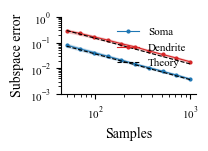

In [186]:
df = pd.DataFrame(results)
subset = df.query(f"nb_neurons == {param_grid['nb_neurons'][0]} and nb_latents == {param_grid['nb_latents'][0]} and mu_s == {param_grid['mu_s'][0]} and mu_d == {param_grid['mu_d'][0]} and sigma_s == {param_grid['sigma_s'][0]} and sigma_d == {param_grid['sigma_d'][0]}")
subset = subset.sort_values("nb_samples")

plt.figure(figsize=(1.75, 1.0))

# Unpack the data for plotting
x = subset["nb_samples"].values
log_nb_samples = np.log(subset["nb_samples"].values)
log_distance_event = np.log(subset["mean_distance_event_FA"].values)
log_distance_burst = np.log(subset["mean_distance_burst_FA"].values)


# Plot the event distance with error bars
plt.plot(subset["nb_samples"], subset["mean_distance_event_FA"], "-o", ms = 2, color='tab:blue', label="Soma")
plt.fill_between(subset["nb_samples"], subset["mean_distance_event_FA"] - subset["std_distance_event_FA"], 
                 subset["mean_distance_event_FA"] + subset["std_distance_event_FA"], color='tab:blue', alpha=0.2)

# Plot the burst distance with error bars
plt.plot(subset["nb_samples"], subset["mean_distance_burst_FA"], "-o", ms=2, color='tab:red', label="Dendrite")
plt.fill_between(subset["nb_samples"], subset["mean_distance_burst_FA"] - subset["std_distance_burst_FA"], 
                 subset["mean_distance_burst_FA"] + subset["std_distance_burst_FA"], color='tab:red', alpha=0.2)




# Theory derivation - events
nb_samples_theory  = np.linspace(subset["nb_samples"].values.min(), subset["nb_samples"].values.max(), num=100)


distance_events = distance_theory_events(nb_samples=nb_samples_theory,
                                         mu_s=subset["mu_s"].values[0], 
                                         sigma_s=subset["sigma_s"].values[0], 
                                         nb_latents=subset["nb_latents"].values[0])

distance_bursts = distance_theory_bursts(nb_samples=nb_samples_theory,
                                         mu_s=subset["mu_s"].values[0], 
                                         mu_d=subset["mu_d"].values[0], 
                                         sigma_s=subset["sigma_s"].values[0], 
                                         sigma_d=subset["sigma_d"].values[0], 
                                         nb_latents=subset["nb_latents"].values[0])

distance_bursts_second_order = distance_theory_bursts_second_order(nb_samples=nb_samples_theory, 
                                         mu_s=subset["mu_s"].values[0], 
                                         mu_d=subset["mu_d"].values[0], 
                                         sigma_s=subset["sigma_s"].values[0], 
                                         sigma_d=subset["sigma_d"].values[0], 
                                         nb_latents=subset["nb_latents"].values[0])

plt.plot(nb_samples_theory, distance_events, "--", color='k', label=r"Theory")
plt.plot(nb_samples_theory, distance_bursts, "--", color='k')
#plt.plot(nb_samples_theory, distance_bursts_second_order, "--", color='tab:green', label=r"Theory (2nd order)")


plt.xscale('log')
plt.yscale('log')
plt.ylim([1e-3, 1])
plt.xlabel("Samples")
plt.ylabel("Subspace error")

sns.despine()
plt.legend(frameon=False, loc='upper right')

plt.savefig("../results/sensitivity_analysis/number_of_samples.svg", dpi=300)

## Number of neurons

In [126]:
param_grid = {"nb_neurons": np.logspace(1.7, 3, num=10, dtype=int),  "nb_samples": [500], "nb_latents":[3], "mu_s": [3.0], "mu_d":[0.0], "sigma_s": [0.2], "sigma_d": [0.2]}

keys = param_grid.keys()
values = param_grid.values()

total = reduce(mul, (len(v) for v in values), 1)

results = []
for combo in tqdm(product(*values), total=total):
    params = dict(zip(keys, combo))
    
    # Run simulation
    out = run_simulation(**params, nb_repeats=100)

    # Store the results along with the parameter combination
    results.append({**params, **out})

save_data(results, "../results/sensitivity_analysis/number_of_neurons_results.pkl")

100%|██████████| 10/10 [03:09<00:00, 18.99s/it]


In [187]:
results = load_data("../results/sensitivity_analysis/number_of_neurons_results.pkl")
param_grid = {"nb_neurons": np.logspace(1.7, 3, num=10, dtype=int),  "nb_samples": [500], "nb_latents":[3], "mu_s": [3.0], "mu_d":[0.0], "sigma_s": [0.2], "sigma_d": [0.2]}

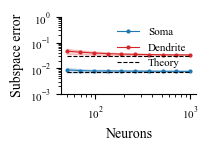

In [188]:
df = pd.DataFrame(results)
subset = df.query(f"nb_samples == {param_grid['nb_samples'][0]} and nb_latents == {param_grid['nb_latents'][0]} and mu_s == {param_grid['mu_s'][0]} and mu_d == {param_grid['mu_d'][0]} and sigma_s == {param_grid['sigma_s'][0]} and sigma_d == {param_grid['sigma_d'][0]}")
subset = subset.sort_values("nb_neurons")

plt.figure(figsize=(1.75, 1.0))

# Unpack the data for plotting
x = subset["nb_neurons"].values
log_nb_neurons = np.log(subset["nb_neurons"].values)
log_distance_event = np.log(subset["mean_distance_event_FA"].values)
log_distance_burst = np.log(subset["mean_distance_burst_FA"].values)


# Plot the event distance with error bars
plt.plot(subset["nb_neurons"], subset["mean_distance_event_FA"], "-o", ms = 2, color='tab:blue', label="Soma")
plt.fill_between(subset["nb_neurons"], subset["mean_distance_event_FA"] - subset["std_distance_event_FA"], 
                 subset["mean_distance_event_FA"] + subset["std_distance_event_FA"], color='tab:blue', alpha=0.2)

# Plot the burst distance with error bars
plt.plot(subset["nb_neurons"], subset["mean_distance_burst_FA"], "-o", ms=2, color='tab:red', label="Dendrite")
plt.fill_between(subset["nb_neurons"], subset["mean_distance_burst_FA"] - subset["std_distance_burst_FA"], 
                 subset["mean_distance_burst_FA"] + subset["std_distance_burst_FA"], color='tab:red', alpha=0.2)


# Theory 
nb_neurons_theory  = np.linspace(subset["nb_neurons"].values.min(), subset["nb_neurons"].values.max(), num=100)

distance_events = distance_theory_events(nb_samples=subset["nb_samples"].values[0], 
                                         mu_s=subset["mu_s"].values[0], 
                                         sigma_s=subset["sigma_s"].values[0], 
                                         nb_latents=subset["nb_latents"].values[0])

distance_bursts = distance_theory_bursts(nb_samples=subset["nb_samples"].values[0],
                                         mu_s=subset["mu_s"].values[0], 
                                         mu_d=subset["mu_d"].values[0], 
                                         sigma_s=subset["sigma_s"].values[0], 
                                         sigma_d=subset["sigma_d"].values[0], 
                                         nb_latents=subset["nb_latents"].values[0])

plt.plot(nb_neurons_theory, distance_events*np.ones_like(nb_neurons_theory), "--", color='k', label=r"Theory")
plt.plot(nb_neurons_theory, distance_bursts*np.ones_like(nb_neurons_theory), "--", color='k')


plt.xscale('log')
plt.yscale('log')
plt.ylim([1e-3, 1])
plt.xlabel("Neurons")
plt.ylabel("Subspace error")

sns.despine()
plt.legend(frameon=False, loc='upper right')

plt.savefig("../results/sensitivity_analysis/number_of_neurons.svg", dpi=300)

## Scaling with baseline burst prob.

In [ ]:
burst_prob_vec = np.linspace(0.01, 0.99, num=10)
mu_d_vec = torch.logit(torch.from_numpy(burst_prob_vec)).numpy()

param_grid = {"nb_neurons": [200],  "nb_samples": [500],  "nb_latents":[3], "mu_s": [3.0], "mu_d":mu_d_vec, "sigma_s": [0.2], "sigma_d": [0.2]}

keys = param_grid.keys()
values = param_grid.values()

total = reduce(mul, (len(v) for v in values), 1)

results = []
for combo in tqdm(product(*values), total=total):
    params = dict(zip(keys, combo))
    
    # Run simulation
    out = run_simulation(**params, nb_repeats=100)

    # Store the results along with the parameter combination
    results.append({**params, **out})

save_data(results, "../results/sensitivity_analysis/baseline_burst_prob_results.pkl")

100%|██████████| 10/10 [02:24<00:00, 14.42s/it]


[0.00848369 0.07650178 0.14362654 0.18861581 0.21435599 0.21293778
 0.18925841 0.13760585 0.07678471 0.00860186]


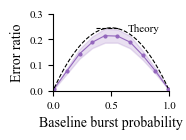

In [123]:
df = pd.DataFrame(results)
subset = df.query(f"nb_neurons == {param_grid['nb_neurons'][0]} and nb_samples == {param_grid['nb_samples'][0]} and nb_latents == {param_grid['nb_latents'][0]} and mu_s == {param_grid['mu_s'][0]} and sigma_s == {param_grid['sigma_s'][0]} and sigma_d == {param_grid['sigma_d'][0]}")
subset = subset.sort_values("mu_d")

plt.figure(figsize=(1.5, 1.0))

# Plot the event distance with error bars
ratio = subset["mean_distance_event_FA"].values / subset["mean_distance_burst_FA"].values
baseline_burst_prob = torch.sigmoid(torch.from_numpy(subset["mu_d"].values))

print(ratio)

plt.plot(baseline_burst_prob, ratio, "-o", ms = 2, color='tab:purple')

ratio_std = ratio * np.sqrt((subset["std_distance_event_FA"].values / subset["mean_distance_event_FA"].values)**2 + (subset["std_distance_burst_FA"].values / subset["mean_distance_burst_FA"].values)**2)

plt.fill_between(baseline_burst_prob, ratio - ratio_std, ratio + ratio_std, color='tab:purple', alpha=0.2)


mu_d_theory  = np.linspace(subset["mu_d"].values.min(), subset["mu_d"].values.max(), num=100)
baseline_burst_prob_theory = sigma(mu_d_theory)

distance_events = distance_theory_events(nb_samples=subset["nb_samples"].values[0], 
                                         mu_s=subset["mu_s"].values[0], 
                                         sigma_s=subset["sigma_s"].values[0], 
                                         nb_latents=subset["nb_latents"].values[0])

distance_bursts = distance_theory_bursts(nb_samples=subset["nb_samples"].values[0], 
                                         mu_s=subset["mu_s"].values[0], 
                                         mu_d=mu_d_theory, 
                                         sigma_s=subset["sigma_s"].values[0], 
                                         sigma_d=subset["sigma_d"].values[0], 
                                         nb_latents=subset["nb_latents"].values[0])


ratio_theory = distance_events / distance_bursts

ratio_theory_second_order = distance_events / distance_bursts_second_order

plt.plot(baseline_burst_prob_theory, ratio_theory, "--", color='k', label=r"Theory")




plt.ylim([0, 0.3])

plt.xlim([0, 1.0])
plt.xlabel("Baseline burst probability")
plt.ylabel("Error ratio")

sns.despine()
plt.legend(frameon=False, loc='upper right')

plt.savefig("../results/sensitivity_analysis/burst_probability.svg", dpi=300)

## Count sparsity

In [ ]:
sparsity = np.logspace(-2, 0, num=10)
mu_s = -1*np.log(sparsity)

param_grid = {"nb_neurons": [50],  "nb_samples": [500], "nb_latents": [3], "mu_s": mu_s, "mu_d":[0.0], "sigma_s": [0.2], "sigma_d": [0.2]}

keys = param_grid.keys()
values = param_grid.values()

total = reduce(mul, (len(v) for v in values), 1)

results = []
for combo in tqdm(product(*values), total=total):
    params = dict(zip(keys, combo))
    
    # Run simulation
    out = run_simulation(**params, nb_repeats=30, variational=True)

    # Store the results along with the parameter combination
    results.append({**params, **out})

save_data(results, "../results/sensitivity_analysis/count_sparsity_results.pkl")

100%|██████████| 10/10 [3:49:54<00:00, 1379.43s/it] 


In [169]:
results = load_data("../results/sensitivity_analysis/count_sparsity_results.pkl")

[-0.8916572  -1.53224605 -2.38913342 -3.16401181 -3.84067228 -4.40243361
 -4.96318035 -5.46172302 -6.01708592 -6.47485172]
[ 0.         -0.51168558 -1.02337115 -1.53505673 -2.0467423  -2.55842788
 -3.07011346 -3.58179903 -4.09348461 -4.60517019]


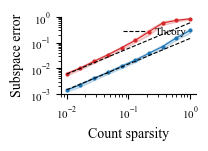

In [170]:
sparsity = np.logspace(-2, 0, num=10)
mu_s = -1*np.log(sparsity)

param_grid = {"nb_neurons": [50],  "nb_samples": [500], "nb_latents": [3], "mu_s": mu_s, "mu_d":[0.0], "sigma_s": [0.2], "sigma_d": [0.2]}

df = pd.DataFrame(results)
subset = df.query(f"nb_neurons == {param_grid['nb_neurons'][0]} and nb_samples == {param_grid['nb_samples'][0]} and nb_latents == {param_grid['nb_latents'][0]} and mu_d == {param_grid['mu_d'][0]} and sigma_s == {param_grid['sigma_s'][0]} and sigma_d == {param_grid['sigma_d'][0]}")
subset = subset.sort_values("mu_s")

plt.figure(figsize=(1.75, 1.0))

# Unpack the data for plotting
x = np.exp(-1*subset["mu_s"].values)
log_nb_neurons = np.log(x)
log_distance_event = np.log(subset["mean_distance_event_FA"].values)
log_distance_burst = np.log(subset["mean_distance_burst_FA"].values)

print(log_distance_event)
print(log_nb_neurons)


# Plot the event distance with error bars
sparsity = np.exp(-subset["mu_s"].values)

mean_distance_event_VI = subset["mean_distance_event_VI"].values
std_distance_event_VI = subset["std_distance_event_VI"].values

plt.plot(sparsity, mean_distance_event_VI, "-o", ms = 2, color='tab:blue', alpha=1.0)
plt.fill_between(sparsity, mean_distance_event_VI - std_distance_event_VI, 
                 mean_distance_event_VI + std_distance_event_VI, color='tab:blue', alpha=0.2)


mean_distance_burst_VI = subset["mean_distance_burst_VI"].values
std_distance_burst_VI = subset["std_distance_burst_VI"].values

plt.plot(sparsity, mean_distance_burst_VI, "-o", ms=2, color='tab:red', alpha=1.0)
plt.fill_between(sparsity, mean_distance_burst_VI - std_distance_burst_VI, 
                 mean_distance_burst_VI + std_distance_burst_VI, color='tab:red', alpha=0.2)

#mean_distance_burst_FA = subset["mean_distance_burst_FA"].values
#std_distance_burst_FA = subset["std_distance_burst_FA"].values

#plt.plot(sparsity, mean_distance_burst_FA, "--", ms=2, color='tab:red', alpha=1.0)
#plt.fill_between(sparsity, mean_distance_burst_FA - std_distance_burst_FA, 
#                 mean_distance_burst_FA + std_distance_burst_FA, color='tab:red', alpha=0.2)



# Theory 
mu_s_theory  = np.linspace(subset["mu_s"].values.min(), subset["mu_s"].values.max(), num=100)
sparsity_theory = np.exp(-mu_s_theory)

distance_events = distance_theory_events(nb_samples=subset["nb_samples"].values[0], 
                                         mu_s=mu_s_theory, 
                                         sigma_s=subset["sigma_s"].values[0], 
                                         nb_latents=subset["nb_latents"].values[0])

distance_bursts = distance_theory_bursts(nb_samples=subset["nb_samples"].values[0], 
                                         mu_s=mu_s_theory, 
                                         mu_d=subset["mu_d"].values[0], 
                                         sigma_s=subset["sigma_s"].values[0], 
                                         sigma_d=subset["sigma_d"].values[0], 
                                         nb_latents=subset["nb_latents"].values[0])

plt.plot(sparsity_theory, distance_events, "--", color='k', label=r"Theory")
plt.plot(sparsity_theory, distance_bursts, "--", color='k')



plt.xscale('log')
plt.yscale('log')
plt.ylim([1e-3, 1])
#plt.xlim([1e-2, 1])
plt.xlabel("Count sparsity")
plt.ylabel("Subspace error")

sns.despine()
plt.legend(frameon=False, loc='upper right')

plt.savefig("../results/sensitivity_analysis/count_sparsity.svg", dpi=300)

[-0.8916572  -1.53224605 -2.38913342 -3.16401181 -3.84067228 -4.40243361
 -4.96318035 -5.46172302 -6.01708592 -6.47485172]
[ 0.         -0.51168558 -1.02337115 -1.53505673 -2.0467423  -2.55842788
 -3.07011346 -3.58179903 -4.09348461 -4.60517019]


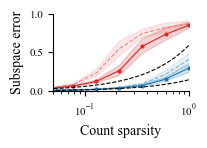

In [171]:
df = pd.DataFrame(results)
subset = df.query(f"nb_neurons == {param_grid['nb_neurons'][0]} and nb_samples == {param_grid['nb_samples'][0]} and nb_latents == {param_grid['nb_latents'][0]} and mu_d == {param_grid['mu_d'][0]} and sigma_s == {param_grid['sigma_s'][0]} and sigma_d == {param_grid['sigma_d'][0]}")
subset = subset.sort_values("mu_s")

plt.figure(figsize=(1.75, 1.0))

# Unpack the data for plotting
x = np.exp(-1*subset["mu_s"].values)
log_nb_neurons = np.log(x)
log_distance_event = np.log(subset["mean_distance_event_FA"].values)
log_distance_burst = np.log(subset["mean_distance_burst_FA"].values)

print(log_distance_event)
print(log_nb_neurons)


# Plot the event distance with error bars
sparsity = np.exp(-subset["mu_s"].values)

alpha = 0.5
plt.plot(sparsity, subset["mean_distance_event_FA"], "--", ms = 2, color='tab:blue', alpha=alpha, label="Soma, FA")
plt.fill_between(sparsity, subset["mean_distance_event_FA"] - subset["std_distance_event_FA"], 
                 subset["mean_distance_event_FA"] + subset["std_distance_event_FA"], color='tab:blue', alpha=alpha/5)

plt.plot(sparsity, subset["mean_distance_event_VI"], "-o", ms = 2, color='tab:blue', alpha=1.0, label="Soma, VI")
plt.fill_between(sparsity, subset["mean_distance_event_VI"] - subset["std_distance_event_VI"], 
                 subset["mean_distance_event_VI"] + subset["std_distance_event_VI"], color='tab:blue', alpha=0.2)

# Plot the burst distance with error bars
plt.plot(sparsity, subset["mean_distance_burst_FA"], "--", ms=2, color='tab:red', alpha=alpha, label="Dendrite, FA")
plt.fill_between(sparsity, subset["mean_distance_burst_FA"] - subset["std_distance_burst_FA"], 
                 subset["mean_distance_burst_FA"] + subset["std_distance_burst_FA"], color='tab:red', alpha=alpha/5)

plt.plot(sparsity, subset["mean_distance_burst_VI"], "-o", ms=2, color='tab:red', alpha=1.0, label="Dendrite, VI")
plt.fill_between(sparsity, subset["mean_distance_burst_VI"] - subset["std_distance_burst_VI"], 
                 subset["mean_distance_burst_VI"] + subset["std_distance_burst_VI"], color='tab:red', alpha=0.2)


# Theory 
mu_s_theory  = np.linspace(subset["mu_s"].values.min(), subset["mu_s"].values.max(), num=100)
sparsity_theory = np.exp(-mu_s_theory)

distance_events = distance_theory_events(nb_samples=subset["nb_samples"].values[0], 
                                         mu_s=mu_s_theory, 
                                         sigma_s=subset["sigma_s"].values[0], 
                                         nb_latents=subset["nb_latents"].values[0])

distance_bursts = distance_theory_bursts(nb_samples=subset["nb_samples"].values[0], 
                                         mu_s=mu_s_theory, 
                                         mu_d=subset["mu_d"].values[0], 
                                         sigma_s=subset["sigma_s"].values[0], 
                                         sigma_d=subset["sigma_d"].values[0], 
                                         nb_latents=subset["nb_latents"].values[0])

plt.plot(sparsity_theory, distance_events, "--", color='k', label=r"Theory")
plt.plot(sparsity_theory, distance_bursts, "--", color='k')



plt.xscale('log')
#plt.yscale('log')
plt.ylim([1e-2, 1])
plt.yticks([0, 0.5, 1])
plt.xlim([5e-2, 1])
plt.xlabel("Count sparsity")
plt.ylabel("Subspace error")

sns.despine()
#plt.legend(frameon=False, loc='upper right')

plt.savefig("../results/sensitivity_analysis/count_sparsity_zoom.svg", dpi=300)

# Number of latents

In [137]:
param_grid = {"nb_neurons": [200],  "nb_samples": [500], "nb_latents":np.arange(1, 11),
               "mu_s": [3.0], "mu_d":[0.0], "sigma_s": [0.2], "sigma_d": [0.2]}

keys = param_grid.keys()
values = param_grid.values()

total = reduce(mul, (len(v) for v in values), 1)

results = []
for combo in tqdm(product(*values), total=total):
    params = dict(zip(keys, combo))
    
    # Run simulation
    out = run_simulation(**params, nb_repeats=100)

    # Store the results along with the parameter combination
    results.append({**params, **out})

save_data(results, "../results/sensitivity_analysis/number_of_latents_results.pkl")

100%|██████████| 10/10 [02:56<00:00, 17.67s/it]


In [172]:
results = load_data("../results/sensitivity_analysis/number_of_latents_results.pkl")
param_grid = {"nb_neurons": [200],  "nb_samples": [500], "nb_latents":np.arange(1, 11),
               "mu_s": [3.0], "mu_d":[0.0], "sigma_s": [0.2], "sigma_d": [0.2]}

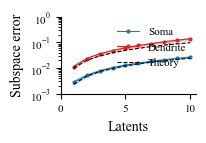

In [173]:
df = pd.DataFrame(results)
subset = df.query(f"nb_neurons == {param_grid['nb_neurons'][0]} and nb_samples == {param_grid['nb_samples'][0]} and mu_s == {param_grid['mu_s'][0]} and mu_d == {param_grid['mu_d'][0]} and sigma_s == {param_grid['sigma_s'][0]} and sigma_d == {param_grid['sigma_d'][0]}")
subset = subset.sort_values("nb_latents")

plt.figure(figsize=(1.75, 1.0))

    
# Plot the event distance with error bars
plt.plot(subset["nb_latents"], subset["mean_distance_event_FA"], "-o", ms = 2, color='tab:blue', label="Soma")
plt.fill_between(subset["nb_latents"], subset["mean_distance_event_FA"] - subset["std_distance_event_FA"], 
                 subset["mean_distance_event_FA"] + subset["std_distance_event_FA"], color='tab:blue', alpha=0.2)

# Plot the burst distance with error bars
plt.plot(subset["nb_latents"], subset["mean_distance_burst_FA"], "-o", ms=2, color='tab:red', label="Dendrite")
plt.fill_between(subset["nb_latents"], subset["mean_distance_burst_FA"] - subset["std_distance_burst_FA"], 
                 subset["mean_distance_burst_FA"] + subset["std_distance_burst_FA"], color='tab:red', alpha=0.2)



nb_latents_theory = param_grid["nb_latents"]

distance_events = distance_theory_events(nb_samples=subset["nb_samples"].values[0], 
                                         mu_s=subset["mu_s"].values[0], 
                                         sigma_s=subset["sigma_s"].values[0], 
                                         nb_latents=nb_latents_theory)

distance_bursts = distance_theory_bursts(nb_samples=subset["nb_samples"].values[0], 
                                         mu_s=subset["mu_s"].values[0], 
                                         mu_d=subset["mu_d"].values[0], 
                                         sigma_s=subset["sigma_s"].values[0], 
                                         sigma_d=subset["sigma_d"].values[0], 
                                         nb_latents=nb_latents_theory)


plt.plot(nb_latents_theory, distance_events, "--", color='k', label=r"Theory")
plt.plot(nb_latents_theory, distance_bursts, "--", color='k')


#plt.xscale('log')
plt.yscale('log')
plt.ylim([1e-3, 1])
plt.xticks([0, 5, 10])
plt.xlabel("Latents")
plt.ylabel("Subspace error")

sns.despine()
plt.legend(frameon=False, loc='upper right')

plt.savefig("../results/sensitivity_analysis/number_of_latents.svg", dpi=300)

# Changing the variance of the weights

In [147]:
sigma_w_vec = np.logspace(-1, 0, num=10)
print(sigma_w_vec)

param_grid = {"nb_neurons": [200], "nb_samples": [500], "nb_latents":[3], "mu_s": [3.0], "mu_d":[0.0], "sigma_s": sigma_w_vec, "sigma_d": [0.2]}

keys = param_grid.keys()
values = param_grid.values()

total = reduce(mul, (len(v) for v in values), 1)

results_soma = []
for combo in tqdm(product(*values), total=total):
    params = dict(zip(keys, combo))
    
    # Run simulation
    out = run_simulation(**params, nb_repeats=100)

    # Store the results along with the parameter combination
    results_soma.append({**params, **out})

save_data(results_soma, "../results/sensitivity_analysis/weight_variance_soma_results.pkl")

[0.1        0.12915497 0.16681005 0.21544347 0.27825594 0.35938137
 0.46415888 0.59948425 0.77426368 1.        ]


100%|██████████| 10/10 [02:29<00:00, 14.96s/it]


In [148]:
sigma_w_vec = np.logspace(-1, 0, num=10)
print(sigma_w_vec)

param_grid = {"nb_neurons": [200], "nb_samples": [500], "nb_latents":[3], "mu_s": [3.0], "mu_d":[0.0], "sigma_s": [0.2], "sigma_d": sigma_w_vec}

keys = param_grid.keys()
values = param_grid.values()

total = reduce(mul, (len(v) for v in values), 1)

results_dendrite = []
for combo in tqdm(product(*values), total=total):
    params = dict(zip(keys, combo))
    
    # Run simulation
    out = run_simulation(**params, nb_repeats=100)

    # Store the results along with the parameter combination
    results_dendrite.append({**params, **out})

save_data(results_dendrite, "../results/sensitivity_analysis/weight_variance_dendrite_results.pkl")

[0.1        0.12915497 0.16681005 0.21544347 0.27825594 0.35938137
 0.46415888 0.59948425 0.77426368 1.        ]


100%|██████████| 10/10 [02:26<00:00, 14.66s/it]


In [174]:
results_soma = load_data("../results/sensitivity_analysis/weight_variance_soma_results.pkl")
results_dendrite = load_data("../results/sensitivity_analysis/weight_variance_dendrite_results.pkl")
param_grid = {"nb_neurons": [200], "nb_samples": [500], "nb_latents":[3], "mu_s": [3.0], "mu_d":[0.0], "sigma_s": [0.2], "sigma_d": sigma_w_vec}

In [175]:
df_soma = pd.DataFrame(results_soma)
subset_soma = df_soma.query(f"nb_neurons == {param_grid['nb_neurons'][0]} and nb_latents == {param_grid['nb_latents'][0]} and mu_s == {param_grid['mu_s'][0]} and mu_d == {param_grid['mu_d'][0]} and sigma_d == 0.2")
subset_soma = subset_soma.sort_values("sigma_s")

df_dendrite = pd.DataFrame(results_dendrite)
subset_dendrite = df_dendrite.query(f"nb_neurons == {param_grid['nb_neurons'][0]} and nb_latents == {param_grid['nb_latents'][0]} and mu_s == {param_grid['mu_s'][0]} and mu_d == {param_grid['mu_d'][0]} and sigma_s == 0.2")
subset_dendrite = subset_dendrite.sort_values("sigma_d")

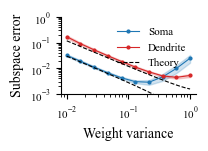

In [176]:
plt.figure(figsize=(1.75, 1.0))

# Plot the event distance with error bars
plt.plot(subset_soma["sigma_s"]**2, subset_soma["mean_distance_event_FA"], "-o", ms = 2, color='tab:blue', label="Soma")
plt.fill_between(subset_soma["sigma_s"]**2, subset_soma["mean_distance_event_FA"] - subset_soma["std_distance_event_FA"], 
                 subset_soma["mean_distance_event_FA"] + subset_soma["std_distance_event_FA"], color='tab:blue', alpha=0.2)

# Plot the burst distance with error bars
plt.plot(subset_dendrite["sigma_d"]**2, subset_dendrite["mean_distance_burst_FA"], "-o", ms=2, color='tab:red', label="Dendrite")
plt.fill_between(subset_dendrite["sigma_d"]**2, subset_dendrite["mean_distance_burst_FA"] - subset_dendrite["std_distance_burst_FA"], 
                 subset_dendrite["mean_distance_burst_FA"] + subset_dendrite["std_distance_burst_FA"], color='tab:red', alpha=0.2)




# Theory derivation - events
sigma_w_theory  = np.linspace(subset_soma["sigma_s"].values.min(), subset_soma["sigma_s"].values.max(), num=100)


distance_events = distance_theory_events(nb_samples=subset_soma["nb_samples"].values[0], 
                                         mu_s=subset_soma["mu_s"].values[0], 
                                         sigma_s=sigma_w_theory, 
                                         nb_latents=subset_soma["nb_latents"].values[0])

distance_bursts = distance_theory_bursts(nb_samples=subset_dendrite["nb_samples"].values[0], 
                                         mu_s=subset_dendrite["mu_s"].values[0], 
                                         mu_d=subset_dendrite["mu_d"].values[0], 
                                         sigma_s=subset_dendrite["sigma_s"].values[0], 
                                         sigma_d=sigma_w_theory, 
                                         nb_latents=subset_dendrite["nb_latents"].values[0])


plt.plot(sigma_w_theory**2, distance_events, "--", color='k', label=r"Theory")
plt.plot(sigma_w_theory**2, distance_bursts, "--", color='k')


plt.xscale('log')
plt.yscale('log')
plt.ylim([1e-3, 1])
plt.xlabel("Weight variance")
plt.ylabel("Subspace error")

sns.despine()
plt.legend(frameon=False, loc='upper right')

plt.savefig("../results/sensitivity_analysis/weight_variance.svg", dpi=300)

## Increasing variance, large samples

In [194]:
sigma_w_vec = np.logspace(-1, 0, num=10)
print(sigma_w_vec)

param_grid = {"nb_neurons": [200], "nb_samples": [20000], "nb_latents":[3], "mu_s": [3.0], "mu_d":[0.0], "sigma_s": sigma_w_vec, "sigma_d": [0.2]}

keys = param_grid.keys()
values = param_grid.values()

total = reduce(mul, (len(v) for v in values), 1)

results_soma = []
for combo in tqdm(product(*values), total=total):
    params = dict(zip(keys, combo))
    
    # Run simulation
    out = run_simulation(**params, nb_repeats=10)

    # Store the results along with the parameter combination
    results_soma.append({**params, **out})

#save_data(results_soma, "../results/sensitivity_analysis/weight_variance_soma_results.pkl")

[0.1        0.12915497 0.16681005 0.21544347 0.27825594 0.35938137
 0.46415888 0.59948425 0.77426368 1.        ]


100%|██████████| 10/10 [03:47<00:00, 22.79s/it]


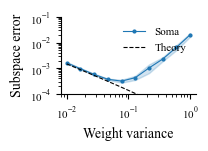

In [192]:
df_soma = pd.DataFrame(results_soma)
subset_soma = df_soma.query(f"nb_neurons == {param_grid['nb_neurons'][0]} and nb_latents == {param_grid['nb_latents'][0]} and mu_s == {param_grid['mu_s'][0]} and mu_d == {param_grid['mu_d'][0]} and sigma_d == 0.2")
subset_soma = subset_soma.sort_values("sigma_s")


plt.figure(figsize=(1.75, 1.0))

# Plot the event distance with error bars
plt.plot(subset_soma["sigma_s"]**2, subset_soma["mean_distance_event_FA"], "-o", ms = 2, color='tab:blue', label="Soma")
plt.fill_between(subset_soma["sigma_s"]**2, subset_soma["mean_distance_event_FA"] - subset_soma["std_distance_event_FA"], 
                 subset_soma["mean_distance_event_FA"] + subset_soma["std_distance_event_FA"], color='tab:blue', alpha=0.2)





# Theory derivation - events
sigma_w_theory  = np.linspace(subset_soma["sigma_s"].values.min(), subset_soma["sigma_s"].values.max(), num=100)


distance_events = distance_theory_events(nb_samples=subset_soma["nb_samples"].values[0], 
                                         mu_s=subset_soma["mu_s"].values[0], 
                                         sigma_s=sigma_w_theory, 
                                         nb_latents=subset_soma["nb_latents"].values[0])



plt.plot(sigma_w_theory**2, distance_events, "--", color='k', label=r"Theory")


plt.xscale('log')
plt.yscale('log')
plt.ylim([1e-4, 1e-1])
plt.xlabel("Weight variance")
plt.ylabel("Subspace error")

sns.despine()
plt.legend(frameon=False, loc='upper right')